# Pal et al. 2021 - Breast Cancer . 03 Signatures
Read module geography off the signature embeddings (raw score_genes scores shown, house (3.5,1.5) linear aspect, external colorbars). **Gate 2**: does the embryonic module pattern appear? Here - a single organized developmental axis (pSom/Gast origin -> Crest terminus) with an inverse terminal Crest gradient: the **non-branching** case (GO, Gate 3 NA).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load manifold (Body with pseudotime)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation','pSom':'Somitogenesis','Crest':'Neural Crest'}
print('body cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g=feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

body cells: 44398 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 80/81 genes present
pSom: 94/98 genes present
Crest: 103/104 genes present


## Gate 2 - module geography
Smoothed spatial correlations (geography), pseudotime gradient, terminal-Crest test, Crest-arm inversion check.

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = ' + f'{np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
proc = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('raw module means (all malignant, from processed):', proc.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
t=adata.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_=spearmanr(t,adata.obs[s]); print('  ' + s + f': rho = {rho:+.3f}')
hi=adata.obs['Crest_sm']>=adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
def _enr(A_,B_):
    az=(adata.obs[A_]-adata.obs[A_].mean())/adata.obs[A_].std()
    bz=(adata.obs[B_]-adata.obs[B_].mean())/adata.obs[B_].std()
    joint=((az>0.5)&(bz>0.5)).mean(); exp=(az>0.5).mean()*(bz>0.5).mean()
    return joint/exp
print(f'joint pSom&Crest-high enrichment = {_enr("pSom","Crest"):.2f} (<1 = inverse terminal gradient)')
print(f'joint Gast&Crest-high enrichment = {_enr("Gast","Crest"):.2f} (>1 would flag Crest enriching the Gast side)')
print(f'joint Gast&pSom-high enrichment  = {_enr("Gast","pSom"):.2f} (~1 = no co-expressing hub)')
crest_gast = np.corrcoef(adata.obs['Crest_sm'],adata.obs['Gast_sm'])[0,1]
# --- Gate 2 / Gate 3 decision tied to the computed geography (no hardcoded call) ---
jpc=_enr('pSom','Crest'); jgp=_enr('Gast','pSom')
crest_decile_pt = tn[hi.values].mean()
rho_crest=spearmanr(t,adata.obs['Crest_sm'])[0]; rho_psom=spearmanr(t,adata.obs['pSom_sm'])[0]
organized      = (rho_crest > 0.5) and (rho_psom < -0.5)   # a single ordered origin->terminus axis
crest_terminal = crest_decile_pt >= 0.7                    # Crest peaks at the terminus
inverse_term   = jpc < 1.0                                 # pSom & Crest mutually exclusive (inverse terminal gradient)
no_hub         = jgp < 1.3                                 # Gast & pSom do not co-express -> no bifurcation hub
gate2 = 'GO' if (organized and crest_terminal and inverse_term) else 'NO-GO'
gate3 = 'NA' if no_hub else 'TEST'
print(f'Gate 2 evidence: organized axis (Crest rho {rho_crest:+.2f}, pSom rho {rho_psom:+.2f})={organized}; '
      f'Crest terminal (decile pt {crest_decile_pt:.2f}>=0.7)={crest_terminal}; inverse terminal (pSom&Crest enrich {jpc:.2f}<1)={inverse_term}')
print(f'Gate 2: single (pSom/Gast origin)->(Crest terminus) developmental axis, non-branching -> {gate2}')
print(f'Gate 3: Gast/pSom hub present={not no_hub} (Gast&pSom enrich {jgp:.2f}) -> {gate3}')
assert gate2=='GO' and gate3=='NA', 'gate call inconsistent with computed geography'
flag = 'FLAG: Crest enriches the Gast side' if crest_gast>0.2 else 'no inversion (Crest tracks the terminus, not the Gast pole)'
print(f'Crest-arm flag: Crest-Gast r = {crest_gast:+.2f} on the Body -> ' + flag)

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.32
  Crest_sm vs Gast_sm: r = +0.04
  Crest_sm vs pSom_sm: r = -0.90
raw module means (all malignant, from processed): {'Gast': -0.0068, 'pSom': 0.0358, 'Crest': -0.0337}
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = +0.270
  pSom_sm: rho = -0.846
  Crest_sm: rho = +0.838
Neural-crest-high decile mean pseudotime = 0.93 (terminal if ~1)
joint pSom&Crest-high enrichment = 0.23 (<1 = inverse terminal gradient)
joint Gast&Crest-high enrichment = 0.40 (>1 would flag Crest enriching the Gast side)
joint Gast&pSom-high enrichment  = 1.03 (~1 = no co-expressing hub)
Gate 2 evidence: organized axis (Crest rho +0.84, pSom rho -0.85)=True; Crest terminal (decile pt 0.93>=0.7)=True; inverse terminal (pSom&Crest enrich 0.23<1)=True
Gate 2: single (pSom/Gast origin)->(Crest terminus) developmental axis, non-branching -> GO
Gate 3: Gast/pSom hub present=False (Gast&pSom enrich 1.03) -> NA
Crest-arm flag: 

### Signature figures - raw scores, house aspect, external colorbars

<cell 5>:13: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<cell 5>:13: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<cell 5>:13: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


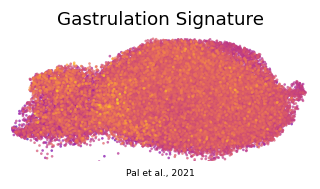

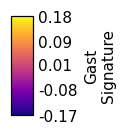

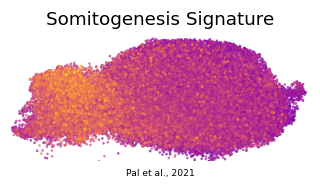

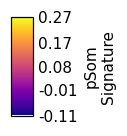

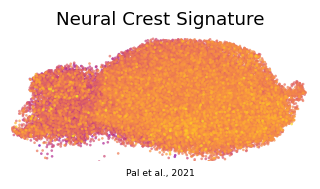

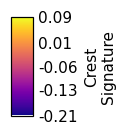

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl=plot.obsm['X_umap']; xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles={'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig,ax=plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=12, colorbar_loc=None, frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Pal et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, m+'_signature.pdf'), bbox_inches='tight')
    lo,hi_=float(adata.obs[m].min()),float(adata.obs[m].max()); ticks=np.round(np.linspace(lo,hi_,5),2)
    fcb=plt.figure(figsize=(.66,1)); cax=fcb.add_axes([.35,.05,.3,.9])
    cb=plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(m+chr(10)+'Signature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, m+'_colorbar.pdf'), bbox_inches='tight')
    print('saved', m+'_signature.pdf', '+ colorbar'); plt.show()

### Save signatures.h5ad

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (44398, 26383)
